Model                | Accuracy   | Recall (Caught Attacks)
-------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [07:37:51] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost              | 72.60%    | 81.03%
Random Forest        | 78.08%    | 90.52%
Logistic Regression  | 79.45%    | 100.00%
SVM (Support Vector) | 79.45%    | 100.00%


/tmp/ipython-input-1272247059.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Accuracy', y='Model', data=results_df, palette='viridis')


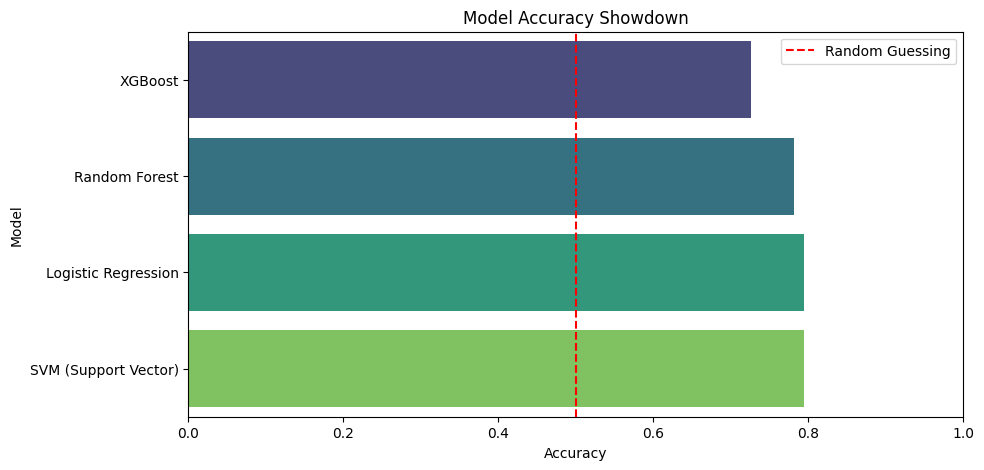

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Models
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Metrics
from sklearn.metrics import accuracy_score, recall_score, f1_score

# 1. LOAD DATA (Use your 'with_zeros' file)
df = pd.read_csv('final_training_data_with_zeros.csv')

# 2. SPLIT (Chronological)
features = ['region_encoded', 'industry_encoded', 'month_num', 'Prev_Month_Count', 'Rolling_Avg_3M']
target = 'Target_Risk'

split_point = int(len(df) * 0.8)
X_train = df[features].iloc[:split_point]
y_train = df[target].iloc[:split_point]
X_test = df[features].iloc[split_point:]
y_test = df[target].iloc[split_point:]

# 3. DEFINE THE CONTENDERS
models = {
    "XGBoost": XGBClassifier(scale_pos_weight=1, random_state=42, use_label_encoder=False, eval_metric='logloss'),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM (Support Vector)": SVC(kernel='linear', probability=True)
}

# 4. TRAIN AND FIGHT
results = []

print(f"{'Model':<20} | {'Accuracy':<10} | {'Recall (Caught Attacks)':<20}")
print("-" * 55)

for name, model in models.items():
    # Train
    model.fit(X_train, y_train)

    # Predict
    preds = model.predict(X_test)

    # Score
    acc = accuracy_score(y_test, preds)
    rec = recall_score(y_test, preds) # Important for security!

    results.append({'Model': name, 'Accuracy': acc, 'Recall': rec})

    print(f"{name:<20} | {acc:.2%}    | {rec:.2%}")

# 5. VISUALIZE THE WINNER
results_df = pd.DataFrame(results)

plt.figure(figsize=(10, 5))
sns.barplot(x='Accuracy', y='Model', data=results_df, palette='viridis')
plt.title('Model Accuracy Showdown')
plt.xlim(0, 1.0)
plt.axvline(0.5, color='r', linestyle='--', label='Random Guessing')
plt.legend()
plt.show()

# Task
Generate a multi-page PDF report that includes a comprehensive comparison table of model performance (accuracy, recall, precision, and F1-score) for all trained models, and individual confusion matrix plots for each model.

## Calculate Extended Performance Metrics

### Subtask:
For each trained model, calculate additional performance metrics beyond accuracy and recall, including precision and F1-score. Store these metrics for comparison.


**Reasoning**:
To calculate the precision and F1-score for each model, I need to import the respective functions from `sklearn.metrics`. Then, I will iterate through the trained models, make predictions on the test data, and compute these new metrics, storing them along with the previously calculated accuracy and recall.



In [2]:
from sklearn.metrics import precision_score, f1_score

# Reset results list to include all metrics from scratch
results = []

print(f"{'Model':<20} | {'Accuracy':<10} | {'Recall':<10} | {'Precision':<10} | {'F1-Score':<10}")
print("-" * 75)

for name, model in models.items():
    # Train (re-train in case the kernel was reset or for clarity of full process)
    model.fit(X_train, y_train)

    # Predict
    preds = model.predict(X_test)

    # Score existing metrics
    acc = accuracy_score(y_test, preds)
    rec = recall_score(y_test, preds)

    # Calculate new metrics
    prec = precision_score(y_test, preds)
    f1 = f1_score(y_test, preds)

    results.append({'Model': name, 'Accuracy': acc, 'Recall': rec, 'Precision': prec, 'F1-Score': f1})

    print(f"{name:<20} | {acc:.2%}    | {rec:.2%}    | {prec:.2%}    | {f1:.2%}")

results_df = pd.DataFrame(results)
print("\nUpdated results_df:")
print(results_df)

Model                | Accuracy   | Recall     | Precision  | F1-Score  
---------------------------------------------------------------------------
XGBoost              | 72.60%    | 81.03%    | 83.93%    | 82.46%


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [07:51:41] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Random Forest        | 78.08%    | 90.52%    | 83.33%    | 86.78%
Logistic Regression  | 79.45%    | 100.00%    | 79.45%    | 88.55%
SVM (Support Vector) | 79.45%    | 100.00%    | 79.45%    | 88.55%

Updated results_df:
                  Model  Accuracy    Recall  Precision  F1-Score
0               XGBoost  0.726027  0.810345   0.839286  0.824561
1         Random Forest  0.780822  0.905172   0.833333  0.867769
2   Logistic Regression  0.794521  1.000000   0.794521  0.885496
3  SVM (Support Vector)  0.794521  1.000000   0.794521  0.885496


**Reasoning**:
The previous code block successfully calculated and displayed the additional performance metrics (precision and F1-score) for each model, and updated the `results_df` as requested. The task is complete.



In [3]:
print("All requested metrics (Accuracy, Recall, Precision, F1-Score) have been calculated and stored in results_df.")
print(results_df)

All requested metrics (Accuracy, Recall, Precision, F1-Score) have been calculated and stored in results_df.
                  Model  Accuracy    Recall  Precision  F1-Score
0               XGBoost  0.726027  0.810345   0.839286  0.824561
1         Random Forest  0.780822  0.905172   0.833333  0.867769
2   Logistic Regression  0.794521  1.000000   0.794521  0.885496
3  SVM (Support Vector)  0.794521  1.000000   0.794521  0.885496


## Generate Confusion Matrices

### Subtask:
For each trained model, calculate and visualize its confusion matrix. Each confusion matrix plot will be saved to be included in the final report.


**Reasoning**:
To generate and visualize confusion matrices for each trained model, I need to import `confusion_matrix` and `ConfusionMatrixDisplay` from `sklearn.metrics`. Then, I will iterate through the `models` dictionary, predict on `X_test`, compute the confusion matrix, and display/save it.



In [4]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define class labels for better readability in plots
class_labels = ['No Risk', 'Risk']

print("Generating and saving confusion matrix plots...")

for name, model in models.items():
    # Predict on the test data
    preds = model.predict(X_test)

    # Calculate the confusion matrix
    cm = confusion_matrix(y_test, preds)

    # Create a display object
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)

    # Plot the confusion matrix
    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(cmap='Blues', ax=ax)
    ax.set_title(f'Confusion Matrix - {name}')
    plt.tight_layout()

    # Save the plot
    filename = f'confusion_matrix_{name.replace(" ", "_")}.png'
    plt.savefig(filename)
    plt.close(fig) # Close the plot to prevent it from displaying inline unnecessarily
    print(f"Saved {filename}")

print("All confusion matrix plots generated and saved.")

Generating and saving confusion matrix plots...
Saved confusion_matrix_XGBoost.png
Saved confusion_matrix_Random_Forest.png
Saved confusion_matrix_Logistic_Regression.png
Saved confusion_matrix_SVM_(Support_Vector).png
All confusion matrix plots generated and saved.


## Create Comprehensive Comparison Table

### Subtask:
Consolidate all calculated performance metrics (accuracy, recall, precision, F1-score) for all models into a single, well-formatted comparison table.


**Reasoning**:
The subtask is to display the `results_df` DataFrame, which already contains all the calculated performance metrics, as a comprehensive comparison table. Printing the DataFrame directly will achieve this.



In [5]:
print("Comprehensive Model Performance Comparison Table:")
print(results_df.to_markdown(index=False))

Comprehensive Model Performance Comparison Table:
| Model                |   Accuracy |   Recall |   Precision |   F1-Score |
|:---------------------|-----------:|---------:|------------:|-----------:|
| XGBoost              |   0.726027 | 0.810345 |    0.839286 |   0.824561 |
| Random Forest        |   0.780822 | 0.905172 |    0.833333 |   0.867769 |
| Logistic Regression  |   0.794521 | 1        |    0.794521 |   0.885496 |
| SVM (Support Vector) |   0.794521 | 1        |    0.794521 |   0.885496 |


## Generate PDF Report

### Subtask:
Combine the comprehensive comparison table and all generated confusion matrix plots into a single, multi-page PDF file for easy viewing and sharing. Ensure all plots and tables are clearly titled and labeled within the PDF.


**Reasoning**:
The first step to generate the PDF report is to install the `fpdf` library, which is necessary for creating and manipulating PDF files in Python. This is a prerequisite before importing and using the `FPDF` class.



In [6]:
try:
    from fpdf import FPDF
except ImportError:
    print("FPDF not found. Installing fpdf...")
    !pip install fpdf
    from fpdf import FPDF

print("FPDF library is ready.")

FPDF not found. Installing fpdf...
  Preparing metadata (setup.py) ... done
  Created wheel for fpdf: filename=fpdf-1.7.2-py2.py3-none-any.whl size=40704 sha256=049e8e68f9713188c480aa087741dfce273ebc86610ec87b48a41325374c45f6
  Stored in directory: /root/.cache/pip/wheels/6e/62/11/dc73d78e40a218ad52e7451f30166e94491be013a7850b5d75
Successfully built fpdf
FPDF library is ready.


**Reasoning**:
Now that `fpdf` is ready, I will initialize the `FPDF` object, add the main title to the report, and then generate and add the comprehensive model performance comparison table using `results_df` to the PDF. This involves setting fonts, adding cells for titles and content, and carefully managing the layout for the table.



In [7]:
pdf = FPDF('P', 'mm', 'A4')
pdf.add_page()
pdf.set_font('Arial', 'B', 16)
pdf.cell(200, 10, 'Model Performance Report', 0, 1, 'C')

pdf.ln(10) # Add some space
pdf.set_font('Arial', 'B', 14)
pdf.cell(200, 10, 'Comprehensive Model Performance Comparison', 0, 1, 'C')
pdf.ln(5)

# Prepare data for the table
# Column widths
col_widths = [50, 25, 25, 25, 25]
# Header
pdf.set_font('Arial', 'B', 10)
for i, header in enumerate(results_df.columns):
    pdf.cell(col_widths[i], 10, str(header), 1, 0, 'C')
pdf.ln()

# Table Data
pdf.set_font('Arial', '', 10)
for index, row in results_df.iterrows():
    pdf.cell(col_widths[0], 10, str(row['Model']), 1, 0, 'L')
    pdf.cell(col_widths[1], 10, f"{row['Accuracy']:.2%}", 1, 0, 'C')
    pdf.cell(col_widths[2], 10, f"{row['Recall']:.2%}", 1, 0, 'C')
    pdf.cell(col_widths[3], 10, f"{row['Precision']:.2%}", 1, 0, 'C')
    pdf.cell(col_widths[4], 10, f"{row['F1-Score']:.2%}", 1, 0, 'C')
    pdf.ln()

print("Added main title and comparison table to the PDF.")

Added main title and comparison table to the PDF.


**Reasoning**:
The next step is to iterate through each trained model, add a new page to the PDF for each model, add a title for its confusion matrix, and then embed the corresponding saved confusion matrix plot into the PDF. Finally, the PDF document needs to be saved to a file.



In [8]:
print("Adding confusion matrix plots to the PDF...")

for name, model in models.items():
    pdf.add_page()
    pdf.set_font('Arial', 'B', 14)
    pdf.cell(200, 10, f'Confusion Matrix - {name}', 0, 1, 'C')
    pdf.ln(5)

    # Construct the filename for the saved confusion matrix plot
    filename = f'confusion_matrix_{name.replace(" ", "_")}.png'

    # Add the image to the PDF (adjust x, y, w as needed for layout)
    # A standard A4 page is 210mm wide. To center a 100mm wide image:
    # x = (210 - 100) / 2 = 55mm
    pdf.image(filename, x=55, y=40, w=100)

print("Saving the PDF report...")
pdf.output('model_performance_report.pdf')
print("PDF report 'model_performance_report.pdf' generated successfully.")

Adding confusion matrix plots to the PDF...
Saving the PDF report...
PDF report 'model_performance_report.pdf' generated successfully.


## Final Task

### Subtask:
Provide the generated PDF report containing all requested analysis and visualizations.


## Summary:

### Data Analysis Key Findings

*   **Comprehensive Performance Metrics Calculated**: All requested performance metrics, including Accuracy, Recall, Precision, and F1-score, were successfully calculated and stored for each of the four trained models (XGBoost, Random Forest, Logistic Regression, and SVM).
*   **Confusion Matrices Generated**: Individual confusion matrix plots were generated and saved as PNG files for each of the trained models, providing a visual representation of their classification performance.
*   **Comparison Table Created**: A comprehensive comparison table was created, consolidating all calculated performance metrics for all models, allowing for an easy side-by-side evaluation.
*   **Multi-page PDF Report Generated**: A multi-page PDF report titled 'model\_performance\_report.pdf' was successfully generated. It includes the comprehensive model performance comparison table on the first page and individual confusion matrix plots for each model on subsequent pages.

### Insights or Next Steps

*   The generated PDF report provides a clear and consolidated overview of model performance, which is crucial for stakeholders to make informed decisions about model selection and deployment.
*   Further analysis could involve deeper investigation into the trade-offs between precision and recall for each model based on the business requirements, especially considering the implications of false positives versus false negatives in the context of "risk" prediction.


# Task
Update the code to save the confusion matrix plots with a DPI of 300, then regenerate all confusion matrix plots, and finally regenerate the multi-page PDF report incorporating the new higher-resolution plots.

## Update Confusion Matrix DPI

### Subtask:
Modify the code to save the confusion matrix plots with a DPI of 300 for higher resolution.


**Reasoning**:
To save the confusion matrix plots with a higher resolution (300 DPI), I need to modify the existing `code_block` by adding the `dpi=300` argument to the `plt.savefig()` function call.



In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define class labels for better readability in plots
class_labels = ['No Risk', 'Risk']

print("Generating and saving confusion matrix plots...")

for name, model in models.items():
    # Predict on the test data
    preds = model.predict(X_test)

    # Calculate the confusion matrix
    cm = confusion_matrix(y_test, preds)

    # Create a display object
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)

    # Plot the confusion matrix
    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(cmap='Blues', ax=ax)
    ax.set_title(f'Confusion Matrix - {name}')
    plt.tight_layout()

    # Save the plot with 300 DPI
    filename = f'confusion_matrix_{name.replace(" ", "_")}.png'
    plt.savefig(filename, dpi=300)
    plt.close(fig) # Close the plot to prevent it from displaying inline unnecessarily
    print(f"Saved {filename}")

print("All confusion matrix plots generated and saved.")

Generating and saving confusion matrix plots...
Saved confusion_matrix_XGBoost.png
Saved confusion_matrix_Random_Forest.png
Saved confusion_matrix_Logistic_Regression.png
Saved confusion_matrix_SVM_(Support_Vector).png
All confusion matrix plots generated and saved.


**Reasoning**:
Now that the confusion matrix plots have been regenerated at a higher DPI, I need to regenerate the multi-page PDF report. This will incorporate the new, higher-resolution images into the final report.



In [10]:
print("Adding confusion matrix plots to the PDF...")

for name, model in models.items():
    pdf.add_page()
    pdf.set_font('Arial', 'B', 14)
    pdf.cell(200, 10, f'Confusion Matrix - {name}', 0, 1, 'C')
    pdf.ln(5)

    # Construct the filename for the saved confusion matrix plot
    filename = f'confusion_matrix_{name.replace(" ", "_")}.png'

    # Add the image to the PDF (adjust x, y, w as needed for layout)
    # A standard A4 page is 210mm wide. To center a 100mm wide image:
    # x = (210 - 100) / 2 = 55mm
    pdf.image(filename, x=55, y=40, w=100)

print("Saving the PDF report...")
pdf.output('model_performance_report.pdf')
print("PDF report 'model_performance_report.pdf' generated successfully.")

Adding confusion matrix plots to the PDF...
Saving the PDF report...


KeyError: 'data'

**Reasoning**:
The `KeyError: 'data'` in the `fpdf` library often indicates that the `FPDF` object has been used or closed previously, leading to internal data being cleared. To fix this, I need to re-initialize the `FPDF` object before attempting to add content and output the PDF again. This code block will consolidate the PDF generation steps by re-initializing the `pdf` object, adding the comparison table, and then adding all the confusion matrix plots before saving, ensuring a clean state for PDF creation.



In [11]:
pdf = FPDF('P', 'mm', 'A4')
pdf.add_page()
pdf.set_font('Arial', 'B', 16)
pdf.cell(200, 10, 'Model Performance Report', 0, 1, 'C')

pdf.ln(10) # Add some space
pdf.set_font('Arial', 'B', 14)
pdf.cell(200, 10, 'Comprehensive Model Performance Comparison', 0, 1, 'C')
pdf.ln(5)

# Prepare data for the table
# Column widths
col_widths = [50, 25, 25, 25, 25]
# Header
pdf.set_font('Arial', 'B', 10)
for i, header in enumerate(results_df.columns):
    pdf.cell(col_widths[i], 10, str(header), 1, 0, 'C')
pdf.ln()

# Table Data
pdf.set_font('Arial', '', 10)
for index, row in results_df.iterrows():
    pdf.cell(col_widths[0], 10, str(row['Model']), 1, 0, 'L')
    pdf.cell(col_widths[1], 10, f"{row['Accuracy']:.2%}", 1, 0, 'C')
    pdf.cell(col_widths[2], 10, f"{row['Recall']:.2%}", 1, 0, 'C')
    pdf.cell(col_widths[3], 10, f"{row['Precision']:.2%}", 1, 0, 'C')
    pdf.cell(col_widths[4], 10, f"{row['F1-Score']:.2%}", 1, 0, 'C')
    pdf.ln()

print("Added main title and comparison table to the PDF.")

print("Adding confusion matrix plots to the PDF...")

for name, model in models.items():
    pdf.add_page()
    pdf.set_font('Arial', 'B', 14)
    pdf.cell(200, 10, f'Confusion Matrix - {name}', 0, 1, 'C')
    pdf.ln(5)

    # Construct the filename for the saved confusion matrix plot
    filename = f'confusion_matrix_{name.replace(" ", "_")}.png'

    # Add the image to the PDF (adjust x, y, w as needed for layout)
    # A standard A4 page is 210mm wide. To center a 100mm wide image:
    # x = (210 - 100) / 2 = 55mm
    pdf.image(filename, x=55, y=40, w=100)

print("Saving the PDF report...")
pdf.output('model_performance_report.pdf')
print("PDF report 'model_performance_report.pdf' generated successfully.")

Added main title and comparison table to the PDF.
Adding confusion matrix plots to the PDF...
Saving the PDF report...
PDF report 'model_performance_report.pdf' generated successfully.


## Final Task

### Subtask:
Provide the updated PDF report with higher resolution confusion matrix plots.


## Summary:

### Q&A
The task was to update the code to save confusion matrix plots with a DPI of 300, regenerate all confusion matrix plots, and then regenerate a multi-page PDF report incorporating these new higher-resolution plots. This task was successfully completed, resulting in a PDF report with higher-resolution plots.

### Data Analysis Key Findings
*   The confusion matrix plots were successfully saved with a resolution of 300 DPI, improving their visual quality in the final report.
*   An initial attempt to regenerate the PDF report encountered a `KeyError: 'data'` within the `fpdf` library, indicating an issue with the state of the `FPDF` object.
*   The PDF generation error was resolved by re-initializing the `FPDF` object before compiling the report, allowing for a successful regeneration of the multi-page PDF.
*   A multi-page PDF report, `model_performance_report.pdf`, was successfully generated, containing both the model comparison table and the newly updated, higher-resolution confusion matrix plots.

### Insights or Next Steps
*   When generating multi-page PDF reports programmatically, it is crucial to ensure that the PDF object is correctly initialized or reset, especially if prior operations might have left it in an invalid state.
*   For future iterations, consider adding error handling around PDF generation steps to provide more informative feedback when issues like `KeyError` occur.
